# Corpus exploration | Coverage and vocabulary

Explore article availability, normalized word counts, section coverage, and common vocabulary. The dataset contains **2,984 source rows**, with **11 records missing an article body** in the supplied snapshot. Analyses use the existing filtering pipeline and leave source CSV values untouched.

The charts describe this collection. They do not establish population-level conclusions about readers or broader news coverage.


## Load visualization and language-processing libraries

Load pandas, Seaborn, Matplotlib, WordCloud and NLTK, then make the tokenizer resources available locally. The unused original utility-module import has been removed.


In [1]:
# Load plotting and NLP packages; download the resources used by the text normalizer.

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
import re
from collections import Counter
import nltk
from nltk.corpus import stopwords
import warnings
warnings.filterwarnings('ignore')

nltk.data.path.append("./data")
nltk.download('punkt', download_dir="./data")
nltk.download("punkt_tab", download_dir="./data")
nltk.download("averaged_perceptron_tagger", download_dir="./data")
nltk.download("averaged_perceptron_tagger_eng", download_dir="./data")
nltk.download('stopwords', download_dir="./data")

[nltk_data] Downloading package punkt to ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable by, or owned by, another account, so a
[nltk_data]     file swapped in during the install would be installed
[nltk_data]     as trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Downloading package punkt_tab to ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable by, or owned by, another account, so a
[nltk_data]     file swapped in during the install would be installed
[nltk_data]     as trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable

False

## Read and filter the article corpus

Load the supplied CSV, normalize missing titles, and discard records without usable article text. The existing pipeline combines each title with its body so both contribute to later token statistics.


In [2]:
# Discard missing article bodies, retain the source metadata, and join titles to article text.

df = pd.read_csv("./data/youth_information_articles.csv", encoding='utf-8-sig')


df['article_title'] = df['article_title'].fillna('').astype(str)



df = df[df['article_body'] != 'N/A']
df = df.dropna(subset=['article_body'])



df['article_body'] = df['article_title'] + " " + df['article_body']

**How to interpret this step.** After filtering, compare the record count with the raw CSV: missing bodies are excluded, but the original CSV is not modified.


## Normalize the text

Apply the original regular expressions, lemmatization, and corpus-specific stopword list. Cleaning removes many function words and site-related terms before lexical summaries are computed.


In [4]:

from pathlib import Path
import nltk
from nltk.stem import WordNetLemmatizer

# Create a private directory for NLTK language resources.
nltk_data_dir = Path.home() / "nltk_data"
nltk_data_dir.mkdir(parents=True, exist_ok=True)

# Restrict access to the current Linux user.
nltk_data_dir.chmod(0o700)

# Prioritize the private resource directory.
if str(nltk_data_dir) not in nltk.data.path:
    nltk.data.path.insert(0, str(nltk_data_dir))

# Download WordNet into the trusted directory.
nltk.download(
    "wordnet",
    download_dir=str(nltk_data_dir),
    raise_on_error=True
)

# Verify that the WordNet lemmatizer works.
lemmatizer = WordNetLemmatizer()

print(lemmatizer.lemmatize("studies"))
print(lemmatizer.lemmatize("cars"))


[nltk_data] Downloading package wordnet to /home/mouelhis/nltk_data...


study
car


In [5]:
# Prepare corpus-specific stopwords and the lemmatization routine without altering its rules.

from nltk.stem import WordNetLemmatizer
from spacy.lang.en.stop_words import STOP_WORDS as SPACY_STOP_WORDS
nltk.download('wordnet', download_dir="./data")








stop_words = set(SPACY_STOP_WORDS)



domain_stopwords = [
    
    'spunout', 'spun', 'out', 'ie', 'ireland', 'irish', 'www', 'http', 'https', 'com', 
    'copyright', 'privacy', 'policy', 'terms', 'conditions', 'login', 'sign', 'register',
    
    
    'page', 'section', 'footer', 'header', 'sidebar', 'widget', 'nav', 'advertisement', 'ad',
    'promo', 'cookie', 'script', 'javascript', 'css', 'html', 'body', 'main', 'published', 'updated',
    'author', 'post', 'article', 'url', 'permalink',
    
    
    
    'day', 'new', 'good', 'bad',
    'check', 'try', 'keep',
    'like', 'just', 'get', 'also', 'would', 'could', 'one', 'make', 'use', 'way', 'well', 
    'time', 'know', 'need', 'really', 'thing', 'think', 'much', 'even', 'still', 'another', 
    'every', 'go', 'want', 'take', 'find', 'look', 'come', 'year', 'old', 'may', 'might',
    
    
    'click', 'read', 'link', 'menu', 'comment', 'reply',
    
    
    'u', 'ur', 'im', 'dont', 'cant', 'wont', 'oh', 'ok', 'please', 'thanks', 'thank', 'yes', 'no'
]


stop_words.update(domain_stopwords)

def normalize_article_text(text):
    """
    Refined text cleaning function.
    Includes explicit removal of separator artifacts (e.g., ___, ///), 
    Normalize text by removing markup and irrelevant tokens, then lemmatize with POS information.
    """
    
    text = str(text).lower()
    
    
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'<.*?>', ' ', text)
    
    
    
    text = re.sub(r'[\_\-\.]{1,}', ' ', text)
    
    text = re.sub(r'[/\\]', ' ', text)

    
    text = re.sub(r"\'", "", text)
    
    
    
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    
    
    text = re.sub(r'\s+[a-z]\s+', ' ', text)
    
    
    words = text.split()
    
    
    
    lemmatizer = WordNetLemmatizer()
    lemmatized_words = [lemmatizer.lemmatize(word) for word in words]
    
    
    
    filtered_words = [word for word in lemmatized_words if word not in stop_words and len(word) > 2]
    
    return " ".join(filtered_words)

print("Cleaning text data (Refined: Separators Removed + Lemmatization + Extended Stopwords)")
df['normalized_text'] = df['article_body'].apply(normalize_article_text)
df.head()

[nltk_data] Downloading package wordnet to ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable by, or owned by, another account, so a
[nltk_data]     file swapped in during the install would be installed
[nltk_data]     as trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).


Cleaning text data (Refined: Separators Removed + Lemmatization + Extended Stopwords)


,article_title,source_section,source_topic,article_body,source_url,normalized_text
0,What losing rugby and finding my ADHD diagnosi...,Voices,Experiences,What losing rugby and finding my ADHD diagnosi...,https://spunout.ie/voices/experiences/losing-r...,losing rugby finding adhd diagnosis taught wee...
1,I didn’t think burnout could happen to someone...,Voices,Experiences,I didn’t think burnout could happen to someone...,https://spunout.ie/voices/experiences/stressor...,didnt burnout happen burnout happened older pe...
2,When heartbreak means putting your safety first,Voices,Experiences,When heartbreak means putting your safety firs...,https://spunout.ie/voices/experiences/heartbre...,heartbreak mean putting safety piece mention s...
3,Growing up in rural Ireland my Irish identity ...,Voices,Experiences,Growing up in rural Ireland my Irish identity ...,https://spunout.ie/voices/experiences/rural-ir...,growing rural identity questioned growing shy ...
4,Heartbreak and healing: How I moved on from my...,Voices,Experiences,Heartbreak and healing: How I moved on from my...,https://spunout.ie/voices/experiences/heartbre...,heartbreak healing moved love growing small to...


**How to interpret this step.** The normalized tokens describe vocabulary after filtering, not the literal distribution of words in the original articles.


## Summarize corpus size and coverage

Compute per-article token counts, overall token volume, average article length, and the distinct source sections and topics.


In [6]:
# Measure normalized article length and coverage across source sections and topics.


df['token_count'] = df['normalized_text'].apply(lambda x: len(x.split()))

total_words = df['token_count'].sum()
avg_words_per_article = df['token_count'].mean()
unique_categories = df['source_section'].nunique()
unique_topics = df['source_topic'].nunique()

print("DATASET STATISTICS")
print(f"Total articles: {len(df)}")
print(f"Total categories: {unique_categories}")
print(f"Total topics: {unique_topics}")
print(f"Total words (after cleaning): {total_words}")
print(f"Average words per article: {avg_words_per_article:.2f}")
print("\nTop 5 categories by article count:")
print(df['source_section'].value_counts())

DATASET STATISTICS
Total articles: 2973
Total categories: 9
Total topics: 63
Total words (after cleaning): 961601
Average words per article: 323.44

Top 5 categories by article count:
source_section
Voices               1290
News                  530
Life                  309
Health                309
Mental_Health         213
Sex_Relationships     115
Employment            114
Education              59
Lgbti                  34
Name: count, dtype: int64


**How to interpret this step.** A large mean article length can be influenced by especially long articles; inspect the length distribution to understand its spread.


## Visualize length and section frequencies

Plot the distribution of normalized token counts and article volume for the ten most common sections. Images are saved to the local `images/` directory.


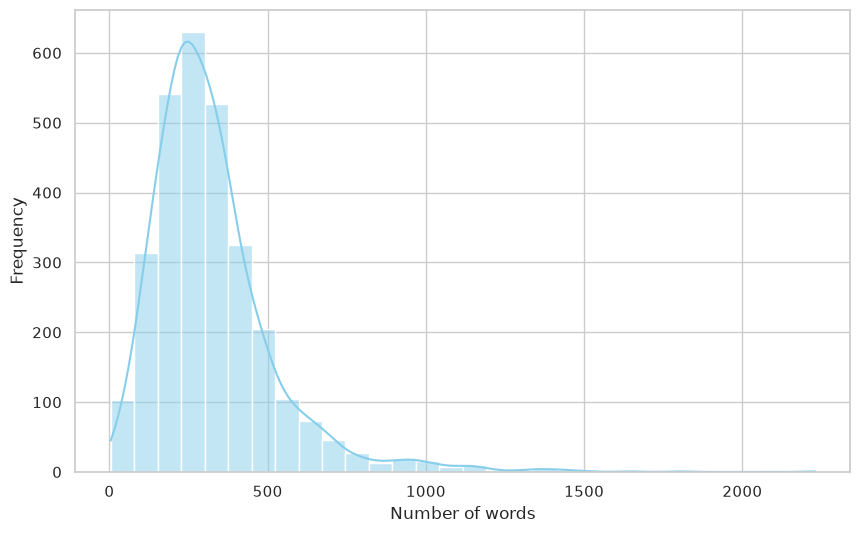

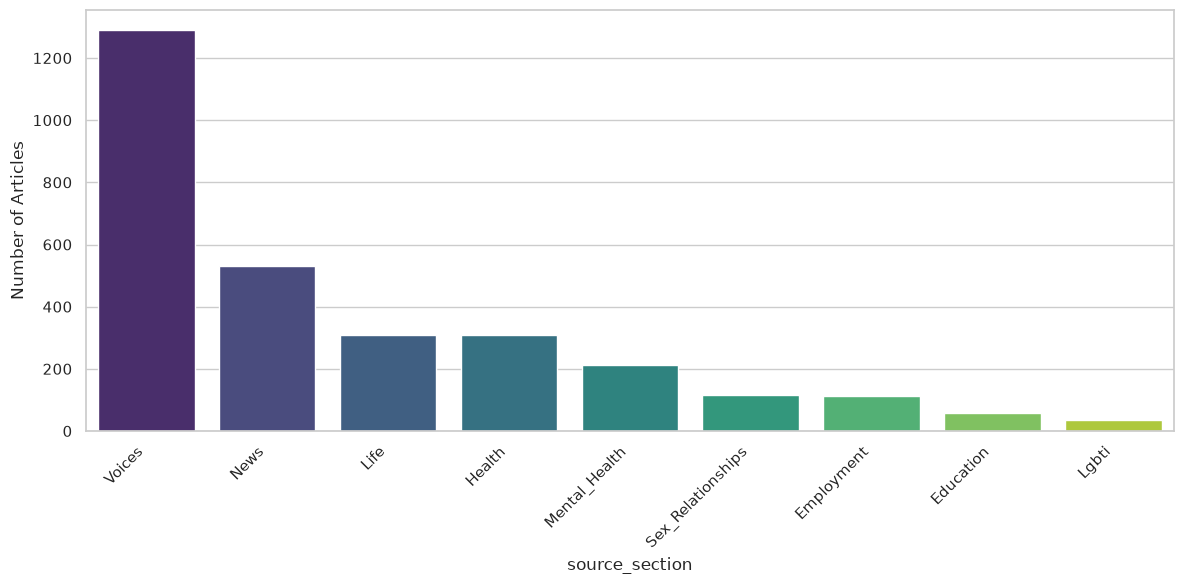

In [7]:
# Create comparable distribution charts and save them to the project images folder.


save_path = './images/'


if not os.path.exists(save_path):
    os.makedirs(save_path)



sns.set(style="whitegrid")


plt.figure(figsize=(10, 6))
sns.histplot(df['token_count'], bins=30, kde=True, color='skyblue')

plt.xlabel('Number of words')
plt.ylabel('Frequency')
plt.savefig(os.path.join(save_path, 'distribution_article_lengths.png'), dpi=300, bbox_inches='tight')
plt.show()


plt.figure(figsize=(12, 6))

top_categories = df['source_section'].value_counts().nlargest(10).index
sns.countplot(data=df[df['source_section'].isin(top_categories)], x='source_section', order=top_categories, palette='viridis')

plt.xlabel('source_section')
plt.ylabel('Number of Articles')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(save_path, 'top_10_categories.png'), dpi=300, bbox_inches='tight')
plt.show()

**How to interpret this step.** Higher article volume reflects coverage in the source snapshot, not necessarily greater importance or audience demand.


## Inspect prominent terms with word clouds

Construct word clouds for the three largest source sections using their normalized article text.


Generating Word Clouds for top categories...


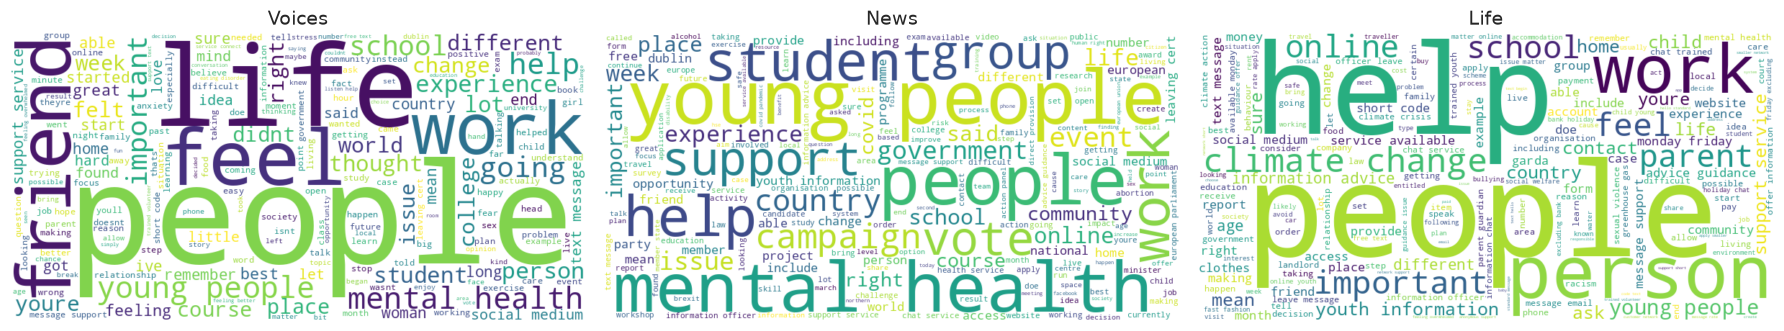

In [8]:
# Build word clouds for the three most represented source sections.


print("Generating Word Clouds for top categories...")
top_3_cats = df['source_section'].value_counts().nlargest(3).index

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes = axes.flatten()


for i, cat in enumerate(top_3_cats):
    
    cat_text = " ".join(df[df['source_section'] == cat]['normalized_text'])
    
    
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(cat_text)
    
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].set_title(f'{cat.replace("_", " ").title()}', fontsize=14)
    axes[i].axis('off')  


plt.tight_layout()
save_path = './images/'
plt.savefig(f'{save_path}/top_3_wordclouds.png', dpi=300, bbox_inches='tight')
plt.show()

**How to interpret this step.** Word-cloud size represents token frequency and is descriptive; it does not prove that a term is uniquely associated with a section.


## List the most frequent normalized tokens

Count normalized tokens across the corpus and display the twenty most common values.


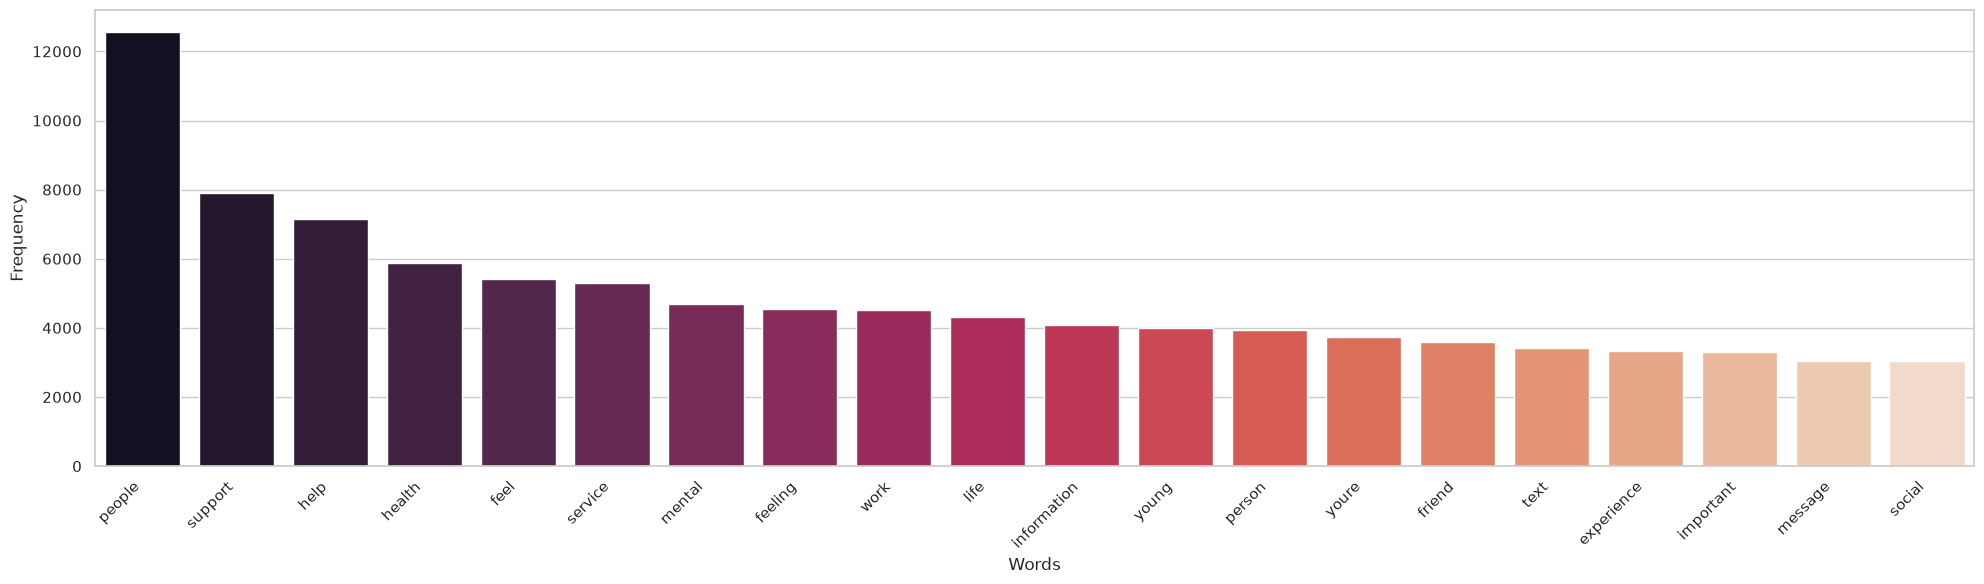

In [9]:
# Count vocabulary occurrences across all cleaned articles and plot the leading terms.


all_words_list = " ".join(df['normalized_text']).split()
word_counts = Counter(all_words_list)
most_common_words = word_counts.most_common(20)
words, counts = zip(*most_common_words)
plt.figure(figsize=(20, 6))
sns.barplot(x=list(words), y=list(counts), palette='rocket')

plt.xlabel('Words')
plt.ylabel('Frequency')


plt.xticks(rotation=45, ha='right') 
plt.tight_layout() 
plt.savefig(os.path.join(save_path, 'top_20_frequent_words.png'), dpi=300, bbox_inches='tight')
plt.show()

**How to interpret this step.** Recurring terms can reveal corpus themes, but a frequency ranking does not account for distinctiveness across documents.
